# 1. Loading Dataset

In [55]:
import pandas as pd
from pathlib import Path

store_data = pd.read_csv("C:\\Users\\kayce\\OneDrive\\Documents\\Sales Forecasting and Business Intelligence\\data\\raw\\Sample_Superstore.csv")

store_data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,12/06/16,16/06/16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [56]:
store_data.shape

(9994, 21)

# 2. Cleaning

In [57]:
store_data.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [58]:
store_data.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [59]:
store_data["Order Date"] = pd.to_datetime(store_data["Order Date"])

C:\Users\kayce\AppData\Local\Temp\ipykernel_5964\911836169.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  store_data["Order Date"] = pd.to_datetime(store_data["Order Date"])


In [60]:
store_data["Ship Date"] = pd.to_datetime(store_data["Ship Date"])

C:\Users\kayce\AppData\Local\Temp\ipykernel_5964\3748270012.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  store_data["Ship Date"] = pd.to_datetime(store_data["Ship Date"])


In [61]:
store_data.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [62]:
store_data.duplicated().sum()

np.int64(0)

In [63]:
store_data.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [64]:
print(((store_data["Discount"] > 1) | (store_data["Discount"] < 0)).sum())

0


In [65]:
print((store_data["Quantity"] <= 0).sum())

0


In [66]:
print((store_data["Quantity"] <= 0).sum())

0


In [67]:
store_data.to_csv(Path(
    "C:\\Users\\kayce\\OneDrive\\Documents\\Sales Forecasting and Business Intelligence\\data\\processed") / "superstore_cleaned.csv",
    index=False
)
print("Shape:", store_data.shape)

Shape: (9994, 21)


# 3. EDA


In [68]:
import matplotlib.pyplot as plt

In [69]:
print(store_data["Order Date"].min())
print(store_data["Order Date"].max())

2014-01-02 00:00:00
2017-12-30 00:00:00


In [70]:
print("Total Orders: ", len(store_data))

Total Orders:  9994


In [71]:
print("Unique Customers: ", store_data["Customer ID"].nunique())

Unique Customers:  793


In [72]:
print("Unique Orders:", store_data["Order ID"].nunique())

Unique Orders: 5009


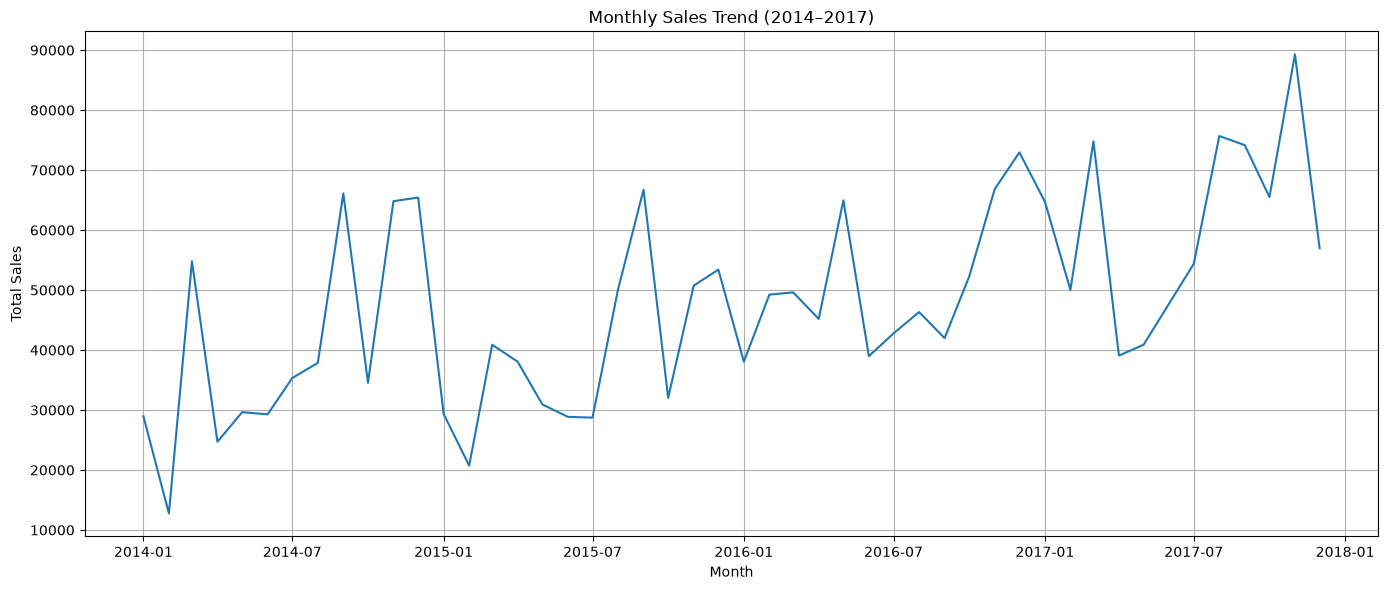

In [73]:
monthly_sales = (store_data.set_index("Order Date")["Sales"].resample("MS").sum())

plt.figure(figsize=(14, 6))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

In [74]:
print("Highest monthly sales:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest monthly sales:")
print(monthly_sales.idxmin(), monthly_sales.min())

print("\nAverage monthly sales:")
print(monthly_sales.mean())

print("\nMonthly sales summary:")
print(monthly_sales.describe())

Highest monthly sales:
2017-11-01 00:00:00 89306.24

Lowest monthly sales:
2014-02-01 00:00:00 12743.108

Average monthly sales:
47858.351256250004

Monthly sales summary:
count       48.000000
mean     47858.351256
std      16893.845067
min      12743.108000
25%      35146.421250
50%      47041.156950
75%      64755.137875
max      89306.240000
Name: Sales, dtype: float64


In [75]:
print(monthly_sales.to_string())

Order Date
2014-01-01    28953.7060
2014-02-01    12743.1080
2014-03-01    54801.9060
2014-04-01    24710.0160
2014-05-01    29639.8340
2014-06-01    29287.0306
2014-07-01    35341.2460
2014-08-01    37854.5475
2014-09-01    66110.2238
2014-10-01    34561.9470
2014-11-01    64817.6185
2014-12-01    65426.3147
2015-01-01    29347.3864
2015-02-01    20728.3520
2015-03-01    40876.6112
2015-04-01    38056.9685
2015-05-01    30933.7145
2015-06-01    28862.1982
2015-07-01    28730.3760
2015-08-01    50094.5280
2015-09-01    66729.3290
2015-10-01    32025.0750
2015-11-01    50732.3090
2015-12-01    53415.6612
2016-01-01    38048.1840
2016-02-01    49238.4100
2016-03-01    49612.0450
2016-04-01    45192.2780
2016-05-01    64964.3218
2016-06-01    38991.9430
2016-07-01    42773.3950
2016-08-01    46339.9884
2016-09-01    41985.1423
2016-10-01    52268.1500
2016-11-01    66837.5850
2016-12-01    72954.1555
2017-01-01    64734.3110
2017-02-01    50011.4894
2017-03-01    74774.0838
2017-04-01    

In [76]:
monthly_growth = monthly_sales.pct_change() * 100
print(monthly_growth.round(2))

Order Date
2014-01-01       NaN
2014-02-01    -55.99
2014-03-01    330.05
2014-04-01    -54.91
2014-05-01     19.95
2014-06-01     -1.19
2014-07-01     20.67
2014-08-01      7.11
2014-09-01     74.64
2014-10-01    -47.72
2014-11-01     87.54
2014-12-01      0.94
2015-01-01    -55.14
2015-02-01    -29.37
2015-03-01     97.20
2015-04-01     -6.90
2015-05-01    -18.72
2015-06-01     -6.70
2015-07-01     -0.46
2015-08-01     74.36
2015-09-01     33.21
2015-10-01    -52.01
2015-11-01     58.41
2015-12-01      5.29
2016-01-01    -28.77
2016-02-01     29.41
2016-03-01      0.76
2016-04-01     -8.91
2016-05-01     43.75
2016-06-01    -39.98
2016-07-01      9.70
2016-08-01      8.34
2016-09-01     -9.40
2016-10-01     24.49
2016-11-01     27.87
2016-12-01      9.15
2017-01-01    -11.27
2017-02-01    -22.74
2017-03-01     49.51
2017-04-01    -47.75
2017-05-01      4.63
2017-06-01     16.78
2017-07-01     13.91
2017-08-01     39.15
2017-09-01     -2.00
2017-10-01    -11.68
2017-11-01     36.34
20

In [77]:
store_data["Year"] = store_data["Order Date"].dt.year

yearly_sales = (store_data.groupby("Year")["Sales"].sum().sort_index())

print(yearly_sales)

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


In [78]:
yearly_growth = yearly_sales.pct_change() * 100

print(yearly_growth.round(2))

Year
2014      NaN
2015    -2.83
2016    29.47
2017    20.36
Name: Sales, dtype: float64


## Monthly and Yearly Sales Trends

### Key Findings

The dataset covers 48 months, from January 2014 to December 2017.

The highest monthly sales were recorded in November 2017, at approximately 89,306.24.

The lowest monthly sales occurred in February 2014, at approximately 12,743.11.

Annual sales decreased by 2.83% in 2015, then increased by 29.47% in 2016 and 20.36% in 2017.

### Business Insights

Sales performance improved considerably after 2015, indicating strong revenue growth in 2016 and 2017. Several years also show relatively high sales toward the end of the year, suggesting a possible seasonal pattern that requires further investigation.

### Business Recommendations

Investigate the factors that contributed to the strong sales growth in 2016 and 2017.

Examine monthly sales patterns to determine whether recurring seasonal trends exist.

Use historical sales patterns to support future demand forecasting and inventory planning.

In [79]:
regional_sales = (
    store_data.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

regional_share = (
    regional_sales / store_data["Sales"].sum()
) * 100

print("Regional Total sales: \n", regional_sales, "\n\n")
print("Percentage Share: \n", regional_share.round(2))

Regional Total sales: 
 Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64 


Percentage Share: 
 Region
West       31.58
East       29.55
Central    21.82
South      17.05
Name: Sales, dtype: float64


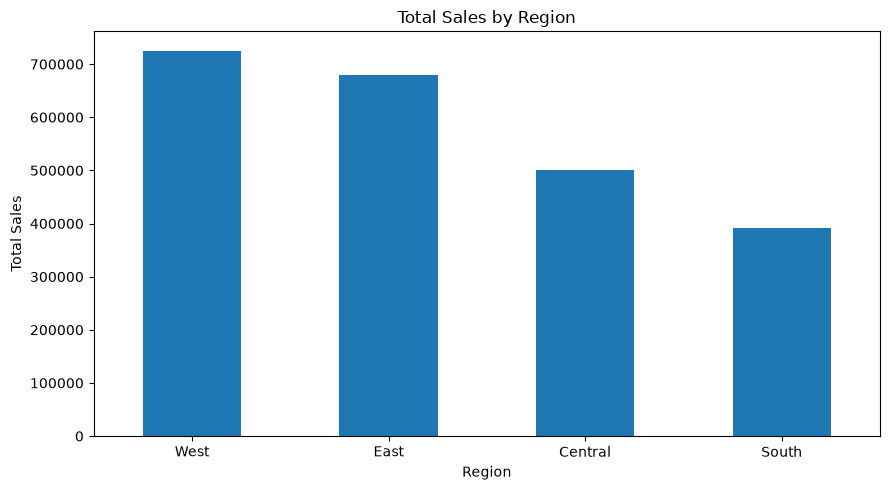

In [80]:
regional_sales.plot(kind="bar", figsize=(9, 5))

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Sales Performance by Region

### Key Findings

West generated the highest sales of 725,457.82, contributing 31.58% of total sales.

East ranked second with sales of 678,781.24, representing 29.55%.

Central generated 501,239.89, accounting for 21.82%.

South recorded the lowest sales of 391,721.91, contributing 17.05%.

West and East together contributed 61.13% of total sales.

### Business Insights

Sales are concentrated in the West and East regions, which together account for over 60% of total revenue. The South region contributes the smallest share, making regional differences an important area for further investigation.

### Business Recommendations

Investigate the factors behind the strong sales performance in the West and East.

Examine product demand, customer segments, and profitability in the South to identify potential improvement opportunities.

Consider regional sales patterns when planning inventory, marketing, and resource allocation.

Note: These findings describe sales revenue, not profitability. Further analysis of profit and other business factors is needed before concluding that one region performs better overall.

In [81]:
category_sales = (
    store_data.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)
category_share = (
    category_sales / store_data["Sales"].sum()
) * 100

print("Sales by Category: \n", category_sales, "\n\n")
print("Percentage of sales by category: \n", category_share.round(2))

Sales by Category: 
 Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64 


Percentage of sales by category: 
 Category
Technology         36.4
Furniture          32.3
Office Supplies    31.3
Name: Sales, dtype: float64


##  Sales Performance by Product Category

### Key Findings

Technology generated the highest sales of 836,154.03, contributing 36.4% of total sales.

Furniture ranked second with sales of 741,999.80, representing 32.3%.

Office Supplies generated 719,047.03, accounting for 31.3% of total sales.

Technology leads Office Supplies by approximately 117,107.00 in sales.

### Business Insights

Technology is the leading product category, contributing the largest share of revenue. However, sales are relatively evenly distributed across the three categories, suggesting that the business generates substantial revenue from a diverse range of products.

### Business Recommendations

Investigate which products within Technology generate the highest sales.

Examine Furniture and Office Supplies for opportunities to increase revenue.

Analyze profit margins alongside sales to identify the most profitable categories.

Consider category-level sales patterns when planning inventory and marketing strategies.

Note: These findings are based on sales revenue only. Higher sales do not necessarily mean higher profitability.

In [82]:
subcategory_sales = (
    store_data.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Sub-Category:")
print(subcategory_sales.round(2))

Sales by Sub-Category:
Sub-Category
Phones         330007.05
Chairs         328449.10
Storage        223843.61
Tables         206965.53
Binders        203412.73
Machines       189238.63
Accessories    167380.32
Copiers        149528.03
Bookcases      114880.00
Appliances     107532.16
Furnishings     91705.16
Paper           78479.21
Supplies        46673.54
Art             27118.79
Envelopes       16476.40
Labels          12486.31
Fasteners        3024.28
Name: Sales, dtype: float64


## Sales Performance by Sub-Category

### Key Findings

Phones recorded the highest sales at 330,007.05.

Chairs ranked second with sales of 328,449.10, closely following Phones.

Storage ranked third with sales of 223,843.61.

Tables and Binders also recorded substantial sales of 206,965.53 and 203,412.73, respectively.

Fasteners recorded the lowest sales at 3,024.28, followed by Labels at 12,486.31 and Envelopes at 16,476.40.

### Business Insights

Sales vary considerably across sub-categories. Phones and Chairs are the leading revenue generators, with each recording sales above 328,000. In contrast, Fasteners, Labels, and Envelopes contribute relatively little revenue. This indicates that sales are concentrated in certain product groups.

### Business Recommendations

Ensure adequate stock availability for high-revenue sub-categories such as Phones and Chairs.

Investigate demand and customer preferences for lower-revenue sub-categories.

Analyze profit margins to determine whether high-revenue products are also highly profitable.

Evaluate inventory levels for low-revenue products before making stocking or discontinuation decisions.

Note: Low sales do not automatically mean a product is unprofitable or should be discontinued. Profitability, demand, and inventory costs should also be considered.

In [83]:
category_profit = (
    store_data.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Category:")
print(category_profit.round(2))

Profit by Category:
Category
Technology         145454.95
Office Supplies    122490.80
Furniture           18451.27
Name: Profit, dtype: float64


## Profitability by Product Category

### Key Findings

Technology generated the highest profit of 145,454.95.

Office Supplies ranked second, generating 122,490.80 in profit.

Furniture generated the lowest profit of 18,451.27, despite ranking second in total sales.

### Business Insights

Technology leads in both sales and profit, making it an important contributor to business performance. Office Supplies generates less revenue than Furniture but substantially more profit. This suggests that sales revenue alone does not adequately explain category performance.

Furniture's relatively low profit compared with its sales warrants further investigation into discounting, product costs, and other factors affecting profitability.

### Business Recommendations

Investigate the factors contributing to Technology's strong profitability.

Examine Furniture's discounts, costs, and sub-category performance to identify opportunities to improve profit.

Evaluate both revenue and profit when making product and inventory decisions.

Analyze profit margins to compare how efficiently each category converts sales into profit.

In [84]:
subcategory_profit = (
    store_data.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Sub-Category:")
print(subcategory_profit.round(2))

Profit by Sub-Category:
Sub-Category
Copiers        55617.82
Phones         44515.73
Accessories    41936.64
Paper          34053.57
Binders        30221.76
Chairs         26590.17
Storage        21278.83
Appliances     18138.01
Furnishings    13059.14
Envelopes       6964.18
Art             6527.79
Labels          5546.25
Machines        3384.76
Fasteners        949.52
Supplies       -1189.10
Bookcases      -3472.56
Tables        -17725.48
Name: Profit, dtype: float64


## Profitability by Sub-Category

### Key Findings

Copiers generated the highest profit at 55,617.82, followed by Phones at 44,515.73 and Accessories at 41,936.64.

Tables recorded the largest loss at -17,725.48.

Bookcases and Supplies also recorded losses of -3,472.56 and -1,189.10, respectively.

Phones generated the highest sales, but Copiers generated the highest profit.

Three sub-categories—Tables, Bookcases, and Supplies—recorded negative total profits.

### Business Insights

High sales do not necessarily translate into high profits. Although Phones lead in sales, Copiers generate more profit. Tables are a particular concern because they generate substantial sales but record the largest loss. This suggests that pricing, discounts, costs, or other operating factors may be affecting profitability.

### Business Recommendations

Investigate Tables' pricing, discount levels, and costs to identify the causes of losses.

Review the profitability of Bookcases and Supplies before making decisions about these products.

Study the factors contributing to Copiers' strong profitability.

Use both sales and profit measures when evaluating product performance and making business decisions.

Note: Negative total profit indicates that the recorded costs and expenses exceed the profit earned for that sub-category over the dataset period. Further analysis is needed to identify the specific causes.

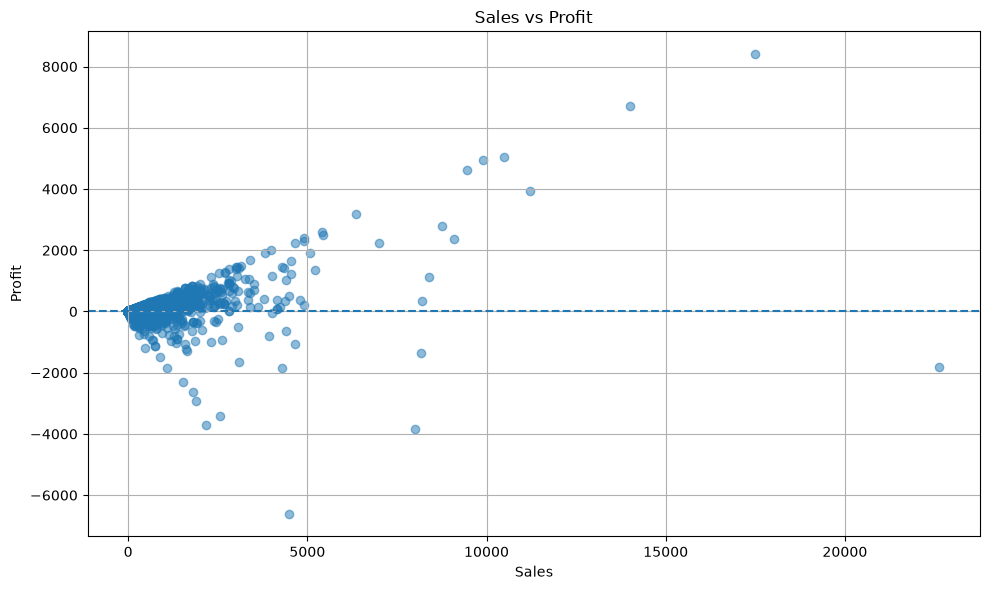

In [85]:
plt.figure(figsize=(10, 6))

plt.scatter(store_data["Sales"], store_data["Profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.axhline(y=0, linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

In [86]:
print("Correlation between Sales and Profit:")
print(store_data["Sales"].corr(store_data["Profit"]).round(3))

print("\nOrders with Negative Profit:")
print((store_data["Profit"] < 0).sum())

print("\nPercentage of Orders with Negative Profit:")
print(round((store_data["Profit"] < 0).mean() * 100, 2), "%")

print("\nHighest Sales:")
print(store_data["Sales"].max())

print("\nLowest Profit:")
print(store_data["Profit"].min())

Correlation between Sales and Profit:
0.479

Orders with Negative Profit:
1871

Percentage of Orders with Negative Profit:
18.72 %

Highest Sales:
22638.48

Lowest Profit:
-6599.978


## Relationship Between Sales and Profit

### Key Findings

The correlation between sales and profit is 0.479, indicating a moderate positive linear relationship.

1,871 orders, representing 18.72% of the dataset, recorded negative profits.

The highest recorded sales value for an individual order was 22,638.48.

The lowest recorded profit for an individual order was -6,599.98.

### Business Insights

The positive correlation suggests that orders with higher sales tend to generate higher profits, although the relationship is not particularly strong. A substantial proportion of orders are unprofitable, indicating that generating sales does not always guarantee a positive financial outcome.

The large negative profit recorded for an individual order highlights the need to investigate transactions that generate significant losses.

### Business Recommendations

Investigate orders with substantial negative profits to identify possible causes, such as high discounts or costs.

Review pricing and discount policies to reduce losses on individual transactions.

Monitor both sales and profit when evaluating order performance.

Investigate whether particular product sub-categories, regions, or customer segments contribute disproportionately to losses.

In [87]:
print("Correlation between Discount and Profit:")
print(store_data["Discount"].corr(store_data["Profit"]).round(3))

print("\nAverage Profit by Discount Level:")
print(
    store_data.groupby("Discount")["Profit"]
    .mean()
    .round(2)
)

print("\nAverage Profit for Discounted vs Non-Discounted Sales:")
print(
    store_data.assign(
        Discount_Status=store_data["Discount"].apply(
            lambda x: "Discounted" if x > 0 else "No Discount"
        )
    ).groupby("Discount_Status")["Profit"].mean().round(2)
)

Correlation between Discount and Profit:
-0.219

Average Profit by Discount Level:
Discount
0.00     66.90
0.10     96.06
0.15     27.29
0.20     24.70
0.30    -45.68
0.32    -88.56
0.40   -111.93
0.45   -226.65
0.50   -310.70
0.60    -43.08
0.70    -95.87
0.80   -101.80
Name: Profit, dtype: float64

Average Profit for Discounted vs Non-Discounted Sales:
Discount_Status
Discounted     -6.66
No Discount    66.90
Name: Profit, dtype: float64


## Impact of Discounts on Profit

### Key Findings

The correlation between discount and profit is -0.219, indicating a weak negative linear relationship.

Sales with no discount recorded an average profit of 66.90.

Discounted sales recorded an average profit of -6.66.

Average profit was negative at discount levels of 30% and above.

The lowest average profit occurred at a 50% discount, at -310.70.

### Business Insights

Discounted sales have a lower average profit than sales without discounts. Higher discount levels generally coincide with negative average profits, suggesting that aggressive discounting may reduce profitability.

However, the relationship is not perfectly consistent across discount levels. Other factors, including product category, costs, and customer purchasing patterns, may also influence profit.

### Business Recommendations

Review discount policies, especially at higher discount levels.

Evaluate whether discounts generate enough additional sales to compensate for reduced profit margins.

Compare discount performance across product categories and sub-categories.

Establish discount limits that consider product costs and target profit margins.

Monitor both revenue and profit when evaluating promotional campaigns.

Note: These results show associations, not proof that discounts alone cause losses. Further analysis is needed to account for other factors.

In [88]:
segment_performance = (
    store_data.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Number_of_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

print(segment_performance.round(2))

             Total_Sales  Total_Profit  Average_Profit  Number_of_Orders
Segment                                                                 
Consumer      1161401.34     134119.21           25.84              2586
Corporate      706146.37      91979.13           30.46              1514
Home Office    429653.15      60298.68           33.82               909


## Sales and Profitability by Customer Segment

### Key Findings

Consumer generated the highest sales of 1,161,401.34 and the highest total profit of 134,119.21.

Corporate generated sales of 706,146.37 and total profit of 91,979.13.

Home Office recorded the lowest sales at 429,653.15 but the highest average profit per dataset record at 33.82.

Consumer had the highest number of unique orders (2,586), followed by Corporate (1,514) and Home Office (909).

Average profit per dataset record was 25.84 for Consumer, 30.46 for Corporate, and 33.82 for Home Office.

### Business Insights

The Consumer segment is the largest contributor to total sales and profit, making it important to overall business performance. However, Home Office has the highest average profit per dataset record despite generating the lowest total revenue. This suggests differences in transaction profitability across customer segments.

### Business Recommendations

Maintain strong customer relationships and sales activity within the Consumer segment.

Investigate the purchasing patterns and product preferences of Home Office customers.

Explore opportunities to grow Home Office sales while maintaining profitability.

Develop targeted marketing strategies based on each segment's purchasing behavior.

Note: Average profit here is calculated per dataset record, not per unique order. An order may contain multiple records, so further order-level analysis would be needed for a direct comparison of average profit per order.

In [89]:
shipmode_performance = (
    store_data.groupby("Ship Mode")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Number_of_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

print(shipmode_performance.round(2))

                Total_Sales  Total_Profit  Average_Profit  Number_of_Orders
Ship Mode                                                                  
Standard Class   1358215.74     164088.79           27.49              2994
Second Class      459193.57      57446.64           29.54               964
First Class       351428.42      48969.84           31.84               787
Same Day          128363.12      15891.76           29.27               264


##  Sales and Profitability by Shipping Mode

### Key Findings

Standard Class generated the highest sales of 1,358,215.74 and the highest total profit of 164,088.79.

Second Class generated sales of 459,193.57 and total profit of 57,446.64.

First Class recorded the highest average profit per dataset record at 31.84.

Same Day recorded the lowest sales of 128,363.12 and total profit of 15,891.76.

Standard Class accounted for the highest number of unique orders (2,994), while Same Day accounted for the lowest (264).

### Business Insights

Standard Class is the largest contributor to sales and total profit, largely serving the greatest number of unique orders. First Class has the highest average profit per dataset record, although this does not necessarily mean it is the most profitable shipping option after accounting for delivery costs.

The lower sales associated with Same Day shipping may reflect lower customer demand or its use for a smaller proportion of orders. Further investigation is needed before drawing conclusions.

### Business Recommendations

Maintain reliable Standard Class shipping because it supports a large share of sales.

Investigate whether First Class shipping provides sufficient value relative to its delivery costs.

Examine demand for Same Day shipping and assess whether its operating costs are justified.

Consider shipping costs and customer satisfaction alongside sales and profit when evaluating shipping methods.

Note: Average profit is calculated per dataset record, not per unique order, and the reported profit does not necessarily account for all shipping-related costs.

In [90]:
monthly_sales_by_year = store_data.pivot_table(
    index=store_data["Order Date"].dt.month,
    columns=store_data["Order Date"].dt.year,
    values="Sales",
    aggfunc="sum"
)

monthly_sales_by_year.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(monthly_sales_by_year.round(2))

Order Date      2014      2015      2016      2017
Jan         28953.71  29347.39  38048.18  64734.31
Feb         12743.11  20728.35  49238.41  50011.49
Mar         54801.91  40876.61  49612.04  74774.08
Apr         24710.02  38056.97  45192.28  39072.00
May         29639.83  30933.71  64964.32  40882.45
Jun         29287.03  28862.20  38991.94  47742.33
Jul         35341.25  28730.38  42773.40  54382.09
Aug         37854.55  50094.53  46339.99  75675.30
Sep         66110.22  66729.33  41985.14  74164.61
Oct         34561.95  32025.08  52268.15  65501.16
Nov         64817.62  50732.31  66837.59  89306.24
Dec         65426.31  53415.66  72954.16  56969.20


In [91]:
regional_profit = (
    store_data.groupby("Region")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum")
    )
)

regional_profit["Profit_Margin_%"] = (
    regional_profit["Total_Profit"]
    / regional_profit["Total_Sales"]
    * 100
)

print(regional_profit.sort_values("Total_Profit", ascending=False).round(2))

         Total_Profit  Total_Sales  Profit_Margin_%
Region                                             
West        108418.45    725457.82            14.94
East         91522.78    678781.24            13.48
South        46749.43    391721.90            11.93
Central      39706.36    501239.89             7.92


## Regional Profitability Analysis

### Key Findings

- **West** generated the highest total profit of **108,418.45**, with sales of **725,457.82** and a profit margin of **14.94%**.
- **East** ranked second in total profit at **91,522.78**, with a profit margin of **13.48%**.
- **South** generated a total profit of **46,749.43** and recorded a profit margin of **11.93%**.
- **Central** generated the lowest total profit of **39,706.36**, despite recording higher sales than the South.
- Central recorded the lowest profit margin at **7.92%**, while West had the highest at **14.94%**.

### Business Insights

West leads in both total sales and profit and has the highest profit margin. Central generates more revenue than South but earns less total profit, suggesting that Central converts its sales into profit less effectively.

The differences in regional profit margins indicate that revenue alone does not fully explain regional performance. Discounts, product mix, and costs may contribute to these differences and require further investigation.

### Business Recommendations

- Investigate the factors contributing to West's strong profit margin.
- Examine Central's discounts, product mix, and costs to identify opportunities to improve profitability.
- Study the South's stronger profit performance relative to Central despite its lower sales.
- Use both total profit and profit margin when evaluating regional performance and allocating resources.

**Note:** Profit margin is calculated as total profit divided by total sales. It measures the proportion of sales retained as profit based on the recorded figures.
